# Lab 1a: the perceptron from scratch

Goal: implement the perceptron in Python, train it on logic gates and see where it fails (XOR).

Cells marked **TODO** are for you to complete. After each of them there is a **check cell**: if it prints `OK`, your code is correct; otherwise you will see an error message.

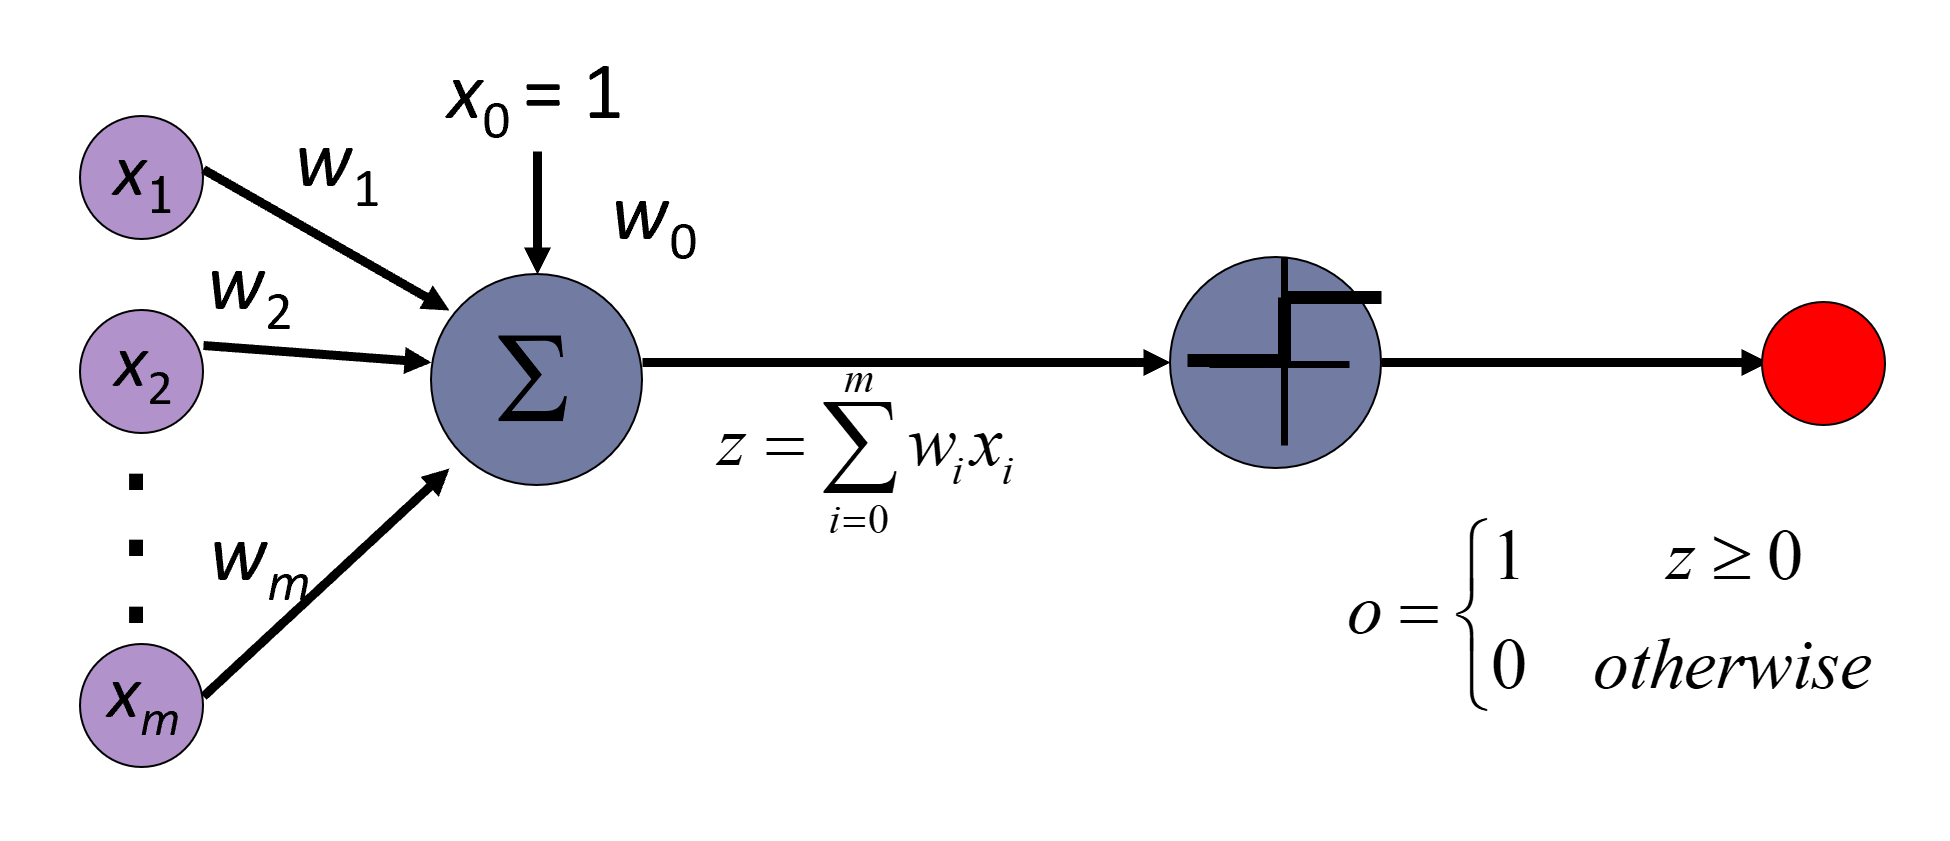

## The model

Inputs $x_1,\dots,x_n$, weights $w_1,\dots,w_n$, bias $b$:

$$z = w_1x_1 + \dots + w_nx_n + b, \qquad \hat y = \begin{cases}1, & z\ge 0\\ 0, & z<0.\end{cases}$$

In NumPy the weighted sum $w_1x_1+\dots+w_nx_n$ is `x @ w` (or `np.dot(x, w)`).
If `X` is a table with one example per row, `X @ w + b` computes $z$ for all examples at once.

In [13]:
import numpy as np
import matplotlib.pyplot as plt

**TODO 1.** Write the step function: it should return `1` where `z >= 0` and `0` elsewhere. It must work both for a single number and for a NumPy array. *Hint:* `(z >= 0)` gives `True/False`; `.astype(int)` turns it into `1/0`.

In [23]:
def step(z):
    z = np.asarray(z)
    # TODO: return 1 where z >= 0, else 0
    return (z >= 0).astype(int)

def predict(X, w, b):
    return step(X @ w + b)

In [24]:
assert step(0.0) == 1 and step(-0.1) == 0 and step(3) == 1
assert list(step(np.array([-2, 0, 2]))) == [0, 1, 1]
print('OK, correct!')

OK, correct!


## 1. Logic gates with hand-chosen weights

**TODO 2.** The weights for AND and OR are given. Find weights `w` and bias `b` for **NAND** (output 0 only for input (1, 1)). *Hint:* NAND is the opposite of AND.

In [25]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

gates = {
    "AND":  (np.array([1, 1]), -1.5),
    "OR":   (np.array([1, 1]), -0.5),
    # TODO: weights and bias for NAND
    "NAND": (np.array([-1, -1]), 1.5),
}
for name, (w, b) in gates.items():
    print(f"{name:5s}", predict(X, w, b))

AND   [0 0 0 1]
OR    [0 1 1 1]
NAND  [1 1 1 0]


In [26]:
assert list(predict(X, *gates["NAND"])) == [1, 1, 1, 0], "NAND should give [1 1 1 0]"
print('OK, correct!')

OK, correct!


## 2. Learning the weights

Perceptron learning rule — for each example, one after another:

1. compute the answer $\hat y$,
2. compute the error $e = d - \hat y$ (it is $-1$, $0$ or $1$),
3. update: $w_i \leftarrow w_i + \eta\, e\, x_i$ for every $i$, and $b \leftarrow b + \eta\, e$.

One pass through all examples is an **epoch**. We stop after an epoch without mistakes.

**TODO 3.** Complete the three lines inside the loop. *Hint:* `w + eta * e * x_j` updates all weights at once.

In [43]:
def fit_perceptron(X, d, eta=1.0, max_epochs=100, w_start=None, b_start=0.0):
    """Returns the weights, the bias and the number of mistakes in each epoch."""
    w = np.zeros(X.shape[1]) if w_start is None else np.array(w_start, dtype=float)
    b = float(b_start)
    mistakes_per_epoch = []
    for epoch in range(max_epochs):
        mistakes = 0
        for x_j, d_j in zip(X, d):
            # TODO: compute the error e, then update w and b
            e = d_j - predict(x_j, w, b)
            w = w + eta * e * x_j
            b = b + eta * e
            mistakes += abs(e)
        mistakes_per_epoch.append(int(mistakes))
        print(f"epoch {epoch}: error = {int(mistakes)}")
        if mistakes == 0:          # a whole epoch without mistakes -> stop
            break
    return w, b, mistakes_per_epoch

In [44]:
d_or = np.array([0, 1, 1, 1])
w, b, hist = fit_perceptron(X, d_or)
print("w =", w, " b =", b)
print("mistakes per epoch:", hist)
assert list(predict(X, w, b)) == [0, 1, 1, 1]
assert list(w) == [1, 1] and b == -1 and hist == [2, 2, 1, 0], "compare with the worked example in the lecture"
print('OK, correct!')

epoch 0: error = 2
epoch 1: error = 2
epoch 2: error = 1
epoch 3: error = 0
w = [1. 1.]  b = -1.0
mistakes per epoch: [2, 2, 1, 0]
OK, correct!


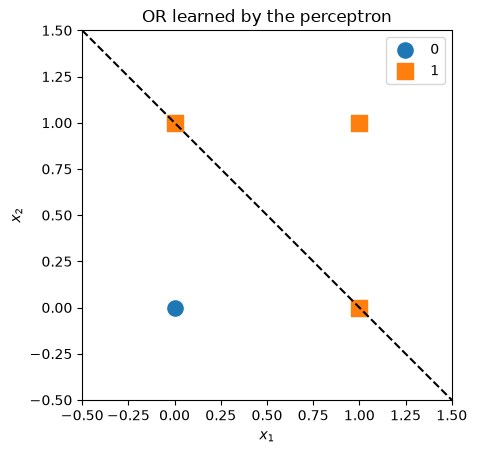

In [45]:
def plot_boundary(X, d, w, b, title=""):
    plt.scatter(*X[d == 0].T, s=120, marker="o", label="0")
    plt.scatter(*X[d == 1].T, s=120, marker="s", label="1")
    xs = np.linspace(-0.5, 1.5, 100)
    if w[1] != 0:                      # w1*x1 + w2*x2 + b = 0  ->  x2 = -(w1*x1 + b) / w2
        plt.plot(xs, -(w[0] * xs + b) / w[1], "k--")
    else:                              # vertical line x1 = -b / w1
        plt.axvline(-b / w[0], color="k", ls="--")
    plt.xlim(-0.5, 1.5); plt.ylim(-0.5, 1.5); plt.gca().set_aspect("equal")
    plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.title(title); plt.legend()
    plt.show()

plot_boundary(X, d_or, w, b, "OR learned by the perceptron")

The learned line passes exactly through (0, 1) and (1, 0): there $z=0$, so the answer is 1. The perceptron stops at *some* line without mistakes — not necessarily the "safest" one.

## 3. Does the learning rate matter?

Run the cell below. When we start from zeros, all weights are simply multiplied by $\eta$ and the answers
(and the mistakes) are exactly the same. Can you explain why? *Hint:* does multiplying $z$ by a positive number change its sign?

In [46]:
for eta in [0.01, 0.1, 1.0, 10.0]:
    w, b, hist = fit_perceptron(X, d_or, eta=eta)
    print(f"eta={eta:5}:  w/eta={w/eta},  b/eta={b/eta:+.1f},  mistakes={hist}")

epoch 0: error = 2
epoch 1: error = 2
epoch 2: error = 1
epoch 3: error = 0
eta= 0.01:  w/eta=[1. 1.],  b/eta=-1.0,  mistakes=[2, 2, 1, 0]
epoch 0: error = 2
epoch 1: error = 2
epoch 2: error = 1
epoch 3: error = 0
eta=  0.1:  w/eta=[1. 1.],  b/eta=-1.0,  mistakes=[2, 2, 1, 0]
epoch 0: error = 2
epoch 1: error = 2
epoch 2: error = 1
epoch 3: error = 0
eta=  1.0:  w/eta=[1. 1.],  b/eta=-1.0,  mistakes=[2, 2, 1, 0]
epoch 0: error = 2
epoch 1: error = 2
epoch 2: error = 1
epoch 3: error = 0
eta= 10.0:  w/eta=[1. 1.],  b/eta=-1.0,  mistakes=[2, 2, 1, 0]


With a random start this is no longer true:

In [47]:
rng = np.random.default_rng(0)
w_rand, b_rand = rng.normal(size=2), rng.normal()
for eta in [0.01, 0.1, 1.0]:
    w, b, hist = fit_perceptron(X, d_or, eta=eta, w_start=w_rand, b_start=b_rand)
    print(f"eta={eta:5}:  epochs={len(hist):3d},  first mistakes={hist[:10]}")

epoch 0: error = 1
epoch 1: error = 1
epoch 2: error = 1
epoch 3: error = 1
epoch 4: error = 1
epoch 5: error = 1
epoch 6: error = 1
epoch 7: error = 1
epoch 8: error = 1
epoch 9: error = 1
epoch 10: error = 1
epoch 11: error = 1
epoch 12: error = 1
epoch 13: error = 1
epoch 14: error = 1
epoch 15: error = 1
epoch 16: error = 1
epoch 17: error = 1
epoch 18: error = 1
epoch 19: error = 1
epoch 20: error = 1
epoch 21: error = 1
epoch 22: error = 1
epoch 23: error = 1
epoch 24: error = 1
epoch 25: error = 1
epoch 26: error = 1
epoch 27: error = 1
epoch 28: error = 1
epoch 29: error = 1
epoch 30: error = 1
epoch 31: error = 1
epoch 32: error = 1
epoch 33: error = 1
epoch 34: error = 1
epoch 35: error = 1
epoch 36: error = 1
epoch 37: error = 1
epoch 38: error = 1
epoch 39: error = 1
epoch 40: error = 1
epoch 41: error = 1
epoch 42: error = 1
epoch 43: error = 1
epoch 44: error = 1
epoch 45: error = 1
epoch 46: error = 1
epoch 47: error = 1
epoch 48: error = 1
epoch 49: error = 1
epoch 50: 

## 4. XOR: the perceptron never stops making mistakes

epoch 0: error = 3
epoch 1: error = 3
epoch 2: error = 4
epoch 3: error = 4
epoch 4: error = 4
epoch 5: error = 4
epoch 6: error = 4
epoch 7: error = 4
epoch 8: error = 4
epoch 9: error = 4
epoch 10: error = 4
epoch 11: error = 4
epoch 12: error = 4
epoch 13: error = 4
epoch 14: error = 4
epoch 15: error = 4
epoch 16: error = 4
epoch 17: error = 4
epoch 18: error = 4
epoch 19: error = 4
epoch 20: error = 4
epoch 21: error = 4
epoch 22: error = 4
epoch 23: error = 4
epoch 24: error = 4
epoch 25: error = 4
epoch 26: error = 4
epoch 27: error = 4
epoch 28: error = 4
epoch 29: error = 4
mistakes per epoch: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
answers: [1 1 0 0]  correct: [0 1 1 0]


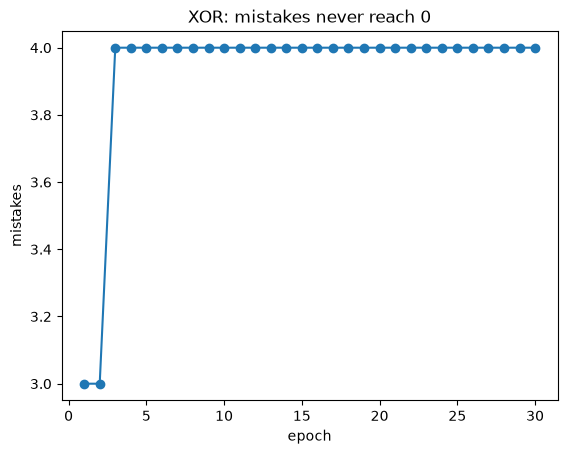

In [48]:
d_xor = np.array([0, 1, 1, 0])
w, b, hist = fit_perceptron(X, d_xor, max_epochs=30)
print("mistakes per epoch:", hist)
print("answers:", predict(X, w, b), " correct:", d_xor)

plt.plot(range(1, len(hist) + 1), hist, "o-")
plt.xlabel("epoch"); plt.ylabel("mistakes"); plt.title("XOR: mistakes never reach 0")
plt.show()

No straight line separates the points with answer 1 from those with answer 0 (see the lecture for a short proof).

## 5. XOR with two layers

$\mathrm{XOR}(x_1,x_2) = \mathrm{AND}\big(\mathrm{OR}(x_1,x_2),\ \mathrm{NAND}(x_1,x_2)\big)$.

**TODO 4.** Compute the hidden layer `h` (two columns: OR and NAND of the inputs) and then the output
(AND applied to `h`). *Hint:* `predict(X, *gates["OR"])` gives OR for all four inputs; `np.column_stack([a, b])` glues two columns together.

In [33]:
def two_layer_xor(X):
    # TODO: hidden layer h = [OR(X), NAND(X)], output = AND(h)
    h = np.column_stack([
        predict(X, *gates["OR"]),
        predict(X, *gates["NAND"])
    ])
    return predict(h, *gates["AND"])

print(two_layer_xor(X))

[0 1 1 0]


In [34]:
assert list(two_layer_xor(X)) == [0, 1, 1, 0]
print('OK, correct!')

OK, correct!


In the hidden representation the two classes *can* be separated by a line. Next lectures: how to **learn** such hidden layers (MLP, gradient descent).

## Homework (separate tasks)

1. Train the perceptron on AND and NAND and plot the learned lines.
2. Change the order of the four training examples (e.g. `X[::-1]`, `d_or[::-1]`). Does the final line change? The number of epochs?
3. **Averaged perceptron:** modify `fit_perceptron` so that it also returns the average of all weight vectors and biases visited during training. Compare its answers on XOR after 30 epochs with the normal perceptron.

## ZADANIE 1
Dla AND:

AND:
w =  [2. 1.] b =  -3.0
Mistakes per epoch:  [2, 3, 3, 2, 1, 0]
Predictions:  [0 0 0 1]


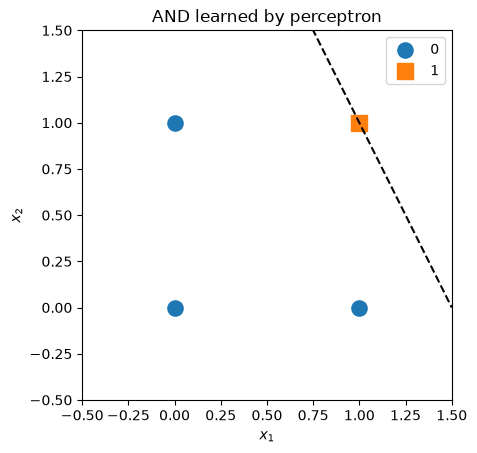

In [35]:
d_and = np.array([0, 0, 0, 1])
w_and, b_and, hist_and = fit_perceptron(X, d_and)

print("AND:")
print("w = ", w_and, "b = ", b_and)
print("Mistakes per epoch: ", hist_and)
print("Predictions: ", predict(X, w_and, b_and))

plot_boundary(X, d_and, w_and, b_and, "AND learned by perceptron")

Dla NAND:

NAND:
w =  [-2. -1.] b =  2.0
Mistakes per epoch:  [1, 3, 3, 2, 1, 0]
Predictions:  [1 1 1 0]


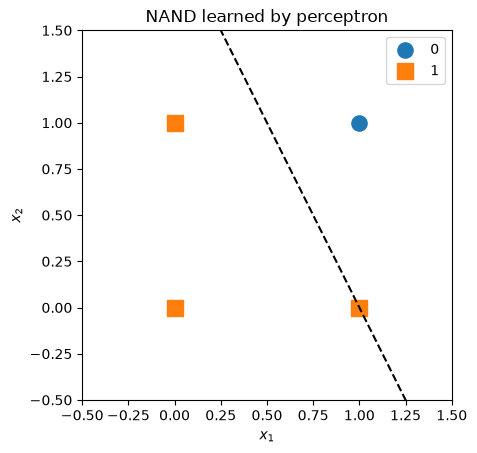

In [36]:
d_nand = np.array([1, 1, 1, 0])
w_nand, b_nand, hist_nand = fit_perceptron(X, d_nand)

print("NAND:")
print("w = ", w_nand, "b = ", b_nand)
print("Mistakes per epoch: ", hist_nand)
print("Predictions: ", predict(X, w_nand, b_nand))

plot_boundary(X, d_nand, w_nand, b_nand, "NAND learned by perceptron")

Sprawdzenie czy klasyfikacja danych jest poprawna:

In [37]:
assert list(predict(X, w_and, b_and)) == [0, 0, 0, 1]
assert list(predict(X, w_nand, b_nand)) == [1, 1, 1, 0]

print("AND and NAND: OK")

AND and NAND: OK


## ZADANIE 2

In [38]:
# OR - oryginalna kolejność:
d_or = np.array([0, 1, 1, 1])
w1, b1, hist1 = fit_perceptron(X, d_or)

# OR - odwrotna kolejność:
w2, b2, hist2 = fit_perceptron(X[::-1], d_or[::-1])

print("Oryginalna kolejnosc:")
print("w = ", w1, "b = ", b1)
print("Epochs: ", len(hist1))
print("Mistakes: ", hist1)

print("\nOdwrtocona kolejnosc:")
print("w = ", w2, "b = ", b2)
print("Epochs: ", len(hist2))
print("Mistakes: ", hist2)

print("\nPredykcje oryginalne: ", predict(X, w1, b1))
print("Predykcje odwrócone: ", predict(X, w2, b2))

Oryginalna kolejnosc:
w =  [1. 1.] b =  -1.0
Epochs:  4
Mistakes:  [2, 2, 1, 0]

Odwrtocona kolejnosc:
w =  [1. 1.] b =  -1.0
Epochs:  3
Mistakes:  [1, 2, 0]

Predykcje oryginalne:  [0 1 1 1]
Predykcje odwrócone:  [0 1 1 1]


Wniosek: Kolejność przykładów może zmienić końcowe wagi i liczbę epok, ale rozwiązanie poprawniekklasyfikuje wszystkie cztery przykłady

## ZADANIE 3

In [39]:
def fit_perceptron_avg(
        X, d, eta=1.0, max_epochs=100,
        w_start=None, b_start=0.0
):
    w = (
        np.zeros(X.shape[1])
        if w_start is None
        else np.array(w_start, dtype=float)
    )
    b = float(b_start)

    mistakes_per_epoch = []
    w_sum = np.zeros_like(w)
    b_sum = 0.0
    count = 0

    for epoch in range(max_epochs):
        mistakes = 0

        for x_j, d_j in zip(X, d):
            e = d_j - predict(x_j, w, b)
            w = w + eta * e * x_j
            b = b + eta * e

            mistakes += abs(e)

            w_sum += w
            b_sum += b
            count += 1

        mistakes_per_epoch.append(int(mistakes))

        if mistakes == 0:
            break

    w_avg = w_sum / count
    b_avg = b_sum / count

    return w_avg, b_avg, mistakes_per_epoch

Porównanie po 30 epokach:

In [42]:
d_xor = np.array([0, 1, 1, 0])

# oryginalny perceptron:
w, b, hist = fit_perceptron(
    X, d_xor, max_epochs=30
)

# uśredniony perceptron:
w_avg, b_avg, hist_avg = fit_perceptron_avg(
    X, d_xor, max_epochs=30
)

print("Oryginalny perceptron: ")
print("w = ", w, "b = ", b)
print("Predykcje: ", predict(X, w, b))
print("Mistakes per epoch: ", hist)

print("\nUsredniony perceptron: ")
print("w_avg = ", w_avg, "b_avg = ", b_avg)
print("Predykcje: ", predict(X, w_avg, b_avg))
print("Mistakes per epoch: ", hist_avg)

Oryginalny perceptron: 
w =  [-1.  0.] b =  0.0
Predykcje:  [1 1 0 0]
Mistakes per epoch:  [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]

Usredniony perceptron: 
w_avg =  [-0.73333333  0.5       ] b_avg =  -0.016666666666666666
Predykcje:  [0 1 0 0]
Mistakes per epoch:  [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


Wniosek: dały różne wyniki, bo inaczej obliczają wagi. Żaden z nich nie rozwiązał poprawnie problemu XOR, bo do tego potrzebna jest sieć z dodatkową warstwą ukrytą.